Structure

In [90]:
#how is the scoring distributed? - histogram opp score
#which countries are better ranked? - rank per country
#which TA stand out? - comparision score/TA
#which combinations stand out? country heatmap x indication
#which variables contribute to the core? comparision bet ponderated variables

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [92]:
df = pd.read_csv("../opportunities_scored.csv")

In [93]:
print("Dataset dimensions:", df.shape)
print("Countries:", df["country"].nunique())
print("Therapeutic areas:", df["therap_area"].nunique())
print("Indications:", df["indication"].nunique())

display(df.head())

Dataset dimensions: (135, 14)
Countries: 9
Therapeutic areas: 5
Indications: 15


,country,therap_area,indication,patient_pop,unmet_need,trial_compet,op_feas,reg_env,patient_pop_norm,unmet_need_norm,op_feas_norm,reg_env_norm,trial_compet_norm,opportunity_score
0,Argentina,Neurology,Multiple sclerosis,11895,71,5,58,70,0.110051,0.597222,0.627907,0.2,0.333333,28.64
1,Argentina,Neurology,Parkinson's disease,17978,85,5,61,70,0.171495,0.791667,0.697674,0.2,0.333333,34.71
2,Argentina,Neurology,Amyotrophic lateral sclerosis,4487,97,3,42,70,0.035222,0.958333,0.255814,0.2,0.666667,32.34
3,Argentina,Rheumatology,Rheumatoid arthritis,27106,62,7,65,70,0.263697,0.472222,0.790698,0.2,0.000000,29.54
4,Argentina,Rheumatology,Systemic lupus erythematosus,16166,84,4,42,70,0.153192,0.777778,0.255814,0.2,0.500000,31.85


In [94]:
df["opportunity_score"].describe().round(2)

count    135.00
mean      36.40
std        7.95
min       19.74
25%       30.78
50%       36.80
75%       41.39
max       53.62
Name: opportunity_score, dtype: float64

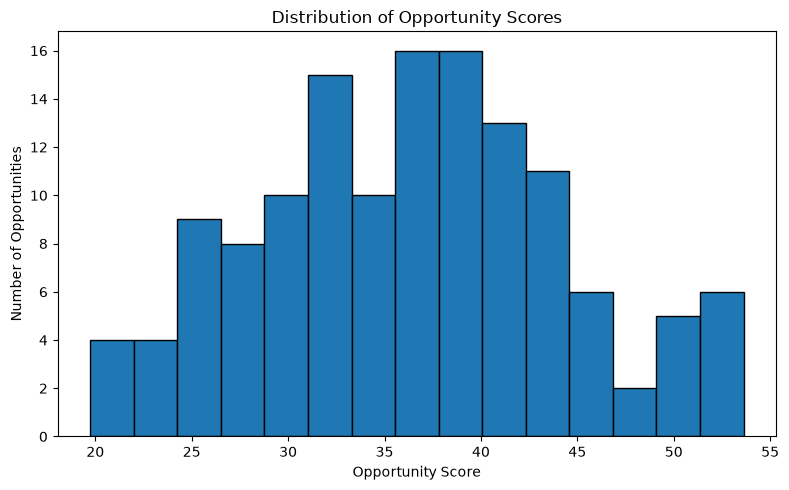

In [95]:
plt.figure(figsize=(8, 5))

plt.hist(df["opportunity_score"], bins=15, edgecolor="black")

plt.title("Distribution of Opportunity Scores")
plt.xlabel("Opportunity Score")
plt.ylabel("Number of Opportunities")

plt.tight_layout()
plt.show()


In [96]:
country_scores = (
    df.groupby("country")["opportunity_score"]
    .median()
    .sort_values(ascending=False)
)

display(country_scores.round(2))

country
Venezuela    46.69
Paraguay     40.46
Mexico       38.81
Colombia     37.81
Ecuador      37.67
Brazil       34.88
Argentina    32.34
Uruguay      27.44
Chile        25.41
Name: opportunity_score, dtype: float64

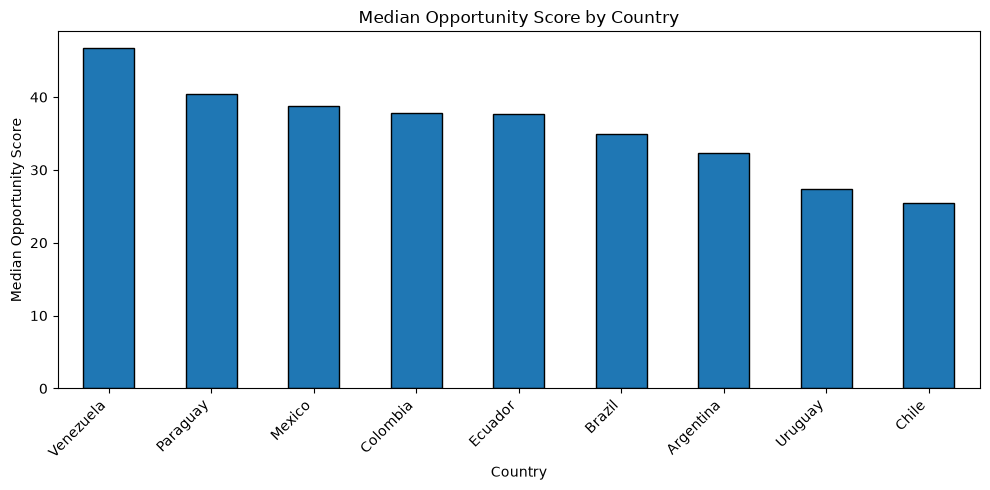

In [97]:
plt.figure(figsize=(10, 5))

country_scores.plot(kind="bar", edgecolor="black")

plt.title("Median Opportunity Score by Country")
plt.xlabel("Country")
plt.ylabel("Median Opportunity Score")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [98]:
area_scores = (
    df.groupby("therap_area")["opportunity_score"]
    .median()
    .sort_values(ascending=False)
)

display(area_scores.round(2))

therap_area
Rheumatology    38.10
Dermatology     38.04
Respiratory     37.93
Neurology       35.98
Oncology        31.10
Name: opportunity_score, dtype: float64

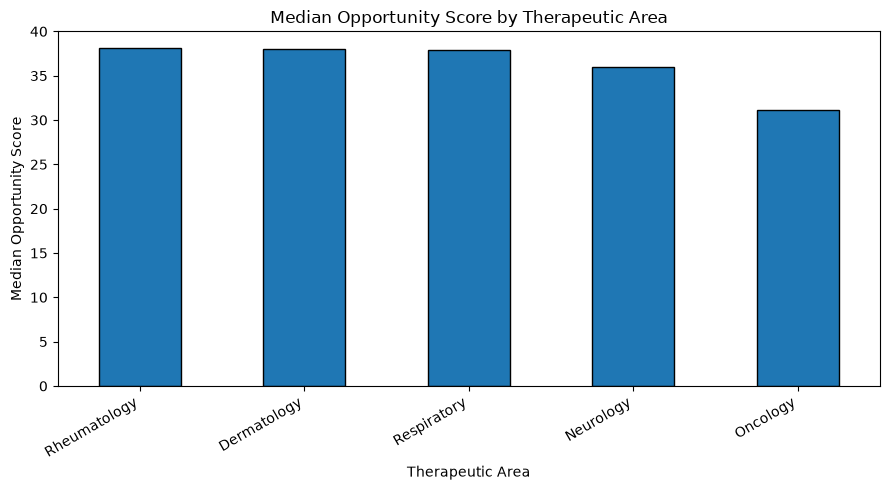

In [99]:
plt.figure(figsize=(9, 5))

area_scores.plot(kind="bar", edgecolor="black")

plt.title("Median Opportunity Score by Therapeutic Area")
plt.xlabel("Therapeutic Area")
plt.ylabel("Median Opportunity Score")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [100]:
indication_scores = (
    df.groupby("indication")["opportunity_score"]
    .median()
    .sort_values(ascending=False)
)

display(indication_scores.round(2))

indication
Atopic dermatitis                        41.17
Systemic lupus erythematosus             40.02
Axial spondyloarthritis                  39.45
Chronic obstructive pulmonary disease    39.21
Amyotrophic lateral sclerosis            38.81
Plaque psoriasis                         37.27
Idiopathic pulmonary fibrosis            37.21
Acne vulgaris                            37.05
Asthma                                   36.80
Parkinson's disease                      34.71
Rheumatoid arthritis                     33.99
Breast cancer                            33.27
Multiple sclerosis                       32.48
Colorectal cancer                        30.64
Non-small cell lung cancer               29.11
Name: opportunity_score, dtype: float64

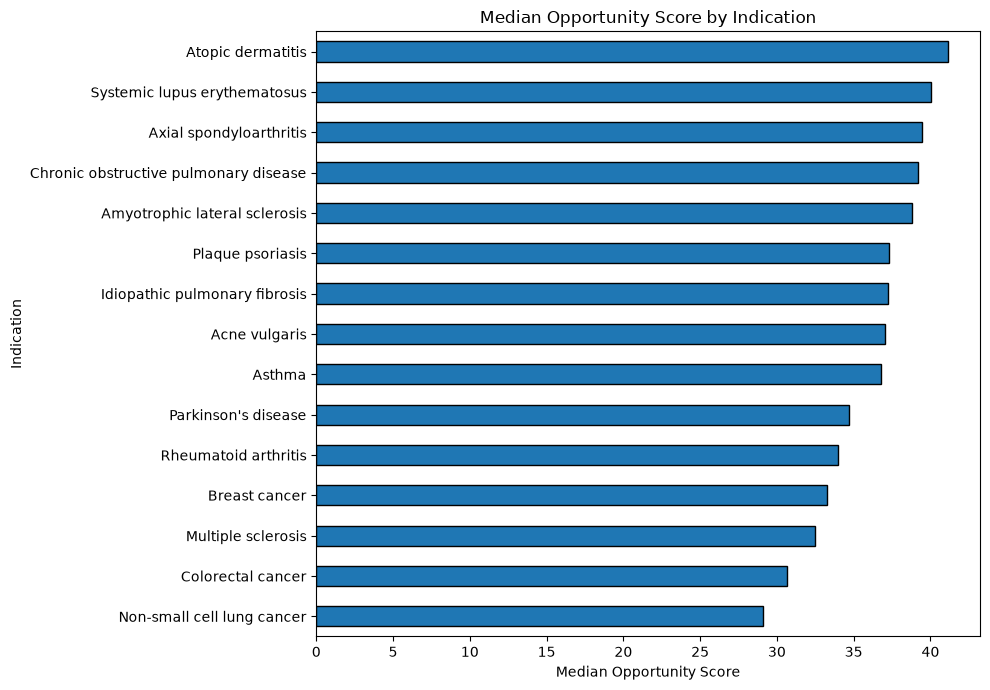

In [101]:
plt.figure(figsize=(10, 7))

indication_scores.plot(kind="barh", edgecolor="black")

plt.title("Median Opportunity Score by Indication")
plt.xlabel("Median Opportunity Score")
plt.ylabel("Indication")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [102]:
heatmap_data = df.pivot_table(
    index="country",
    columns="therap_area",
    values="opportunity_score",
    aggfunc="median"
)

display(heatmap_data.round(2))

therap_area,Dermatology,Neurology,Oncology,Respiratory,Rheumatology
country,,,,,
Argentina,38.04,32.34,26.66,34.99,31.85
Brazil,46.26,32.54,31.10,50.44,34.88
Chile,24.37,28.88,20.14,29.22,29.66
Colombia,37.81,37.04,31.93,37.93,38.48
Ecuador,37.27,41.87,33.27,39.21,40.02
Mexico,42.89,33.25,31.14,43.28,41.37
Paraguay,38.96,42.93,40.52,40.84,40.42
Uruguay,27.39,28.42,26.11,24.86,30.83
Venezuela,52.18,49.53,44.42,51.05,46.64


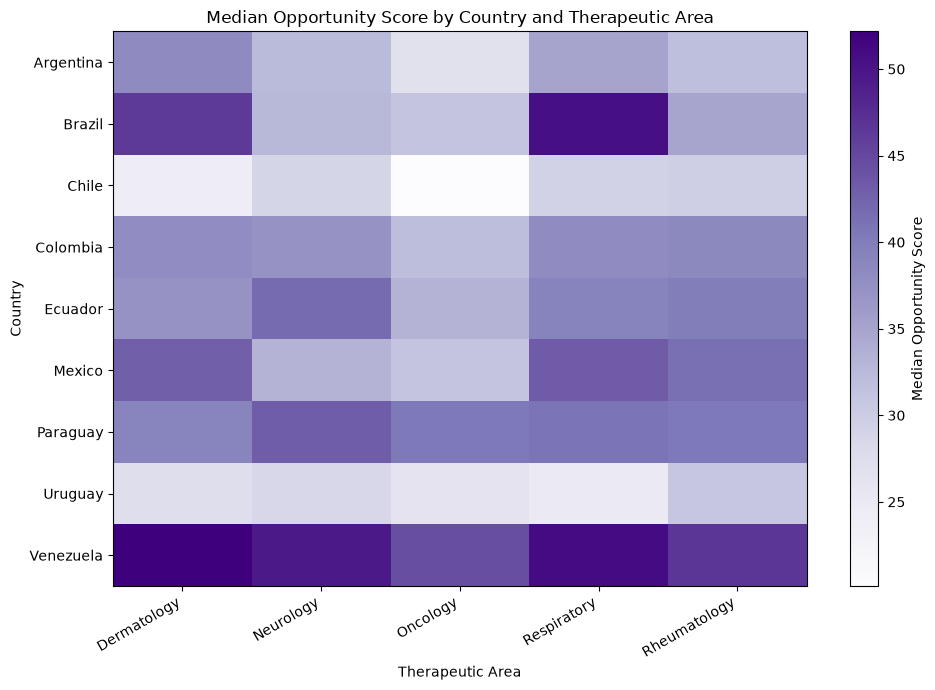

In [103]:
plt.figure(figsize=(10, 7))

plt.imshow(
    heatmap_data,
    aspect="auto",
    cmap="Purples"
)

plt.colorbar(label="Median Opportunity Score")

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns,
    rotation=30,
    ha="right"
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

plt.title("Median Opportunity Score by Country and Therapeutic Area")
plt.xlabel("Therapeutic Area")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [104]:

top_opportunities = (
    df.nlargest(15, "opportunity_score")
    [
        [
            "country",
            "therap_area",
            "indication",
            "opportunity_score",
            "patient_pop",
            "unmet_need",
            "trial_compet",
            "op_feas",
            "reg_env"
        ]
    ]
    .reset_index(drop=True)
)

display(top_opportunities.round(2))

,country,therap_area,indication,opportunity_score,patient_pop,unmet_need,trial_compet,op_feas,reg_env
0,Venezuela,Dermatology,Acne vulgaris,53.62,42675,36,3,53,50
1,Brazil,Respiratory,Asthma,52.92,96481,44,7,68,72
2,Brazil,Dermatology,Acne vulgaris,52.83,100000,39,7,66,72
3,Venezuela,Respiratory,Chronic obstructive pulmonary disease,52.72,29758,69,3,42,50
4,Venezuela,Dermatology,Atopic dermatitis,52.18,30172,50,3,56,50
5,Venezuela,Neurology,Amyotrophic lateral sclerosis,51.75,2969,99,1,36,50
6,Venezuela,Respiratory,Idiopathic pulmonary fibrosis,51.05,4087,89,1,40,50
7,Brazil,Respiratory,Chronic obstructive pulmonary disease,50.44,74141,69,6,63,72
8,Venezuela,Rheumatology,Systemic lupus erythematosus,50.18,11922,85,2,37,50
9,Mexico,Dermatology,Atopic dermatitis,49.60,70977,58,6,61,68


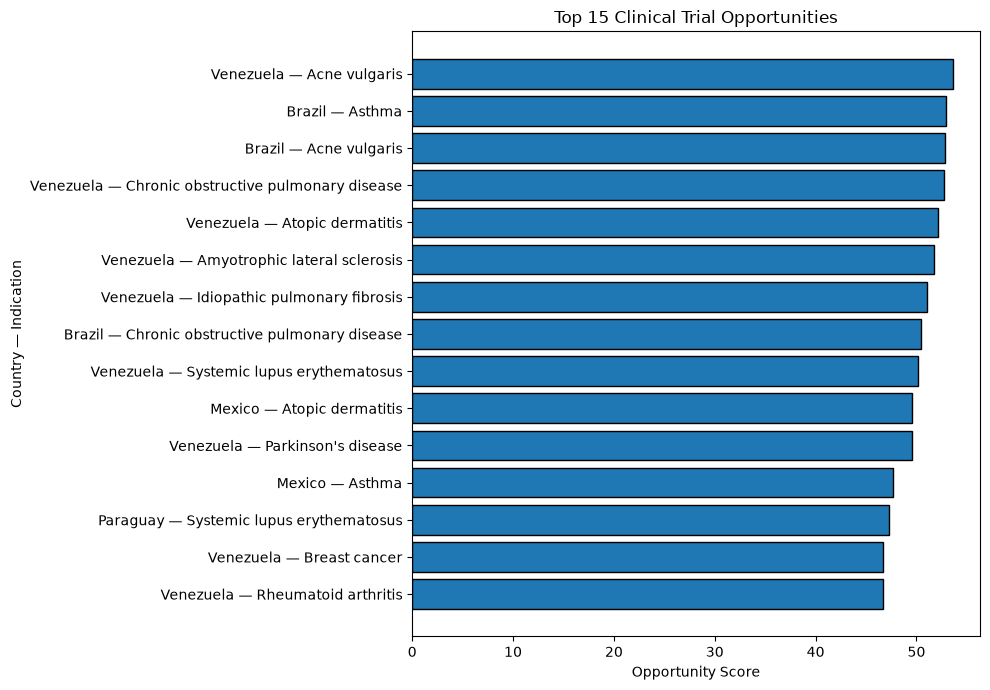

In [105]:

plot_data = top_opportunities.copy()

plot_data["opportunity"] = (
    plot_data["country"] + " — " + plot_data["indication"]
)

plot_data = plot_data.sort_values("opportunity_score")

plt.figure(figsize=(10, 7))
plt.barh(
    plot_data["opportunity"],
    plot_data["opportunity_score"],
    edgecolor="black"
)
plt.title("Top 15 Clinical Trial Opportunities")
plt.xlabel("Opportunity Score")
plt.ylabel("Country — Indication")
plt.tight_layout()
plt.show()

In [115]:
#comparision

features = [
    "patient_pop",
    "unmet_need",
    "trial_compet",
    "op_feas",
    "reg_env"
]

display(
    df[features]
    .describe()
    .drop(index="mean")
    .round(2)
)

,patient_pop,unmet_need,trial_compet,op_feas,reg_env
count,135.00,135.00,135.00,135.00,135.00
std,19543.71,16.87,1.91,9.34,7.76
min,1000.00,28.00,1.00,31.00,50.00
25%,6606.50,57.00,3.00,50.00,62.00
50%,14497.00,68.00,4.00,57.00,68.00
75%,27826.00,81.00,6.00,63.00,72.00
max,100000.00,100.00,7.00,74.00,75.00


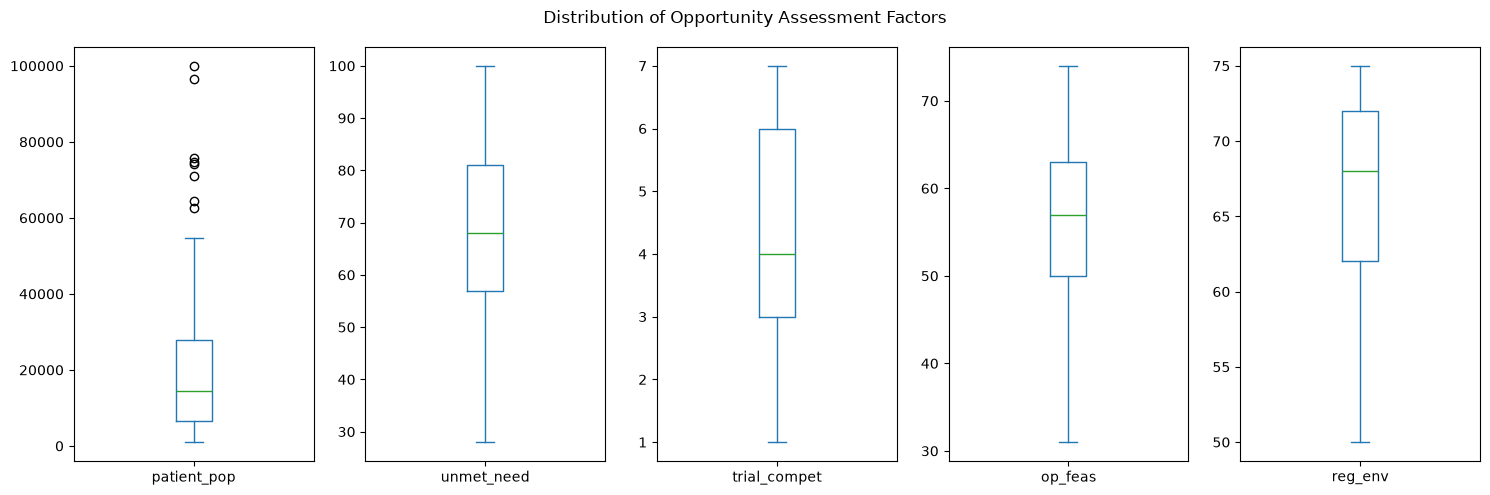

In [116]:
#visualize 

df[features].plot(
    kind="box",
    subplots=True,
    layout=(1, 5),
    figsize=(15, 5),
    sharey=False
)

plt.suptitle("Distribution of Opportunity Assessment Factors")
plt.tight_layout()
plt.show()

In [ ]:
#control point
print("Missing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Patient population range:")
print("Minimum:", df["patient_pop"].min())
print("Maximum:", df["patient_pop"].max())

Missing values:


country              0
therap_area          0
indication           0
patient_pop          0
unmet_need           0
trial_compet         0
op_feas              0
reg_env              0
patient_pop_norm     0
unmet_need_norm      0
op_feas_norm         0
reg_env_norm         0
trial_compet_norm    0
opportunity_score    0
dtype: int64

Duplicate rows: 0
Patient population range:
Minimum: 1000
Maximum: 100000
